In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [2]:
def load_diabetes_data():
    url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
    columns = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
    data = pd.read_csv(url, header=None, names=columns)
    print(data.head())
    return data

In [3]:
data = load_diabetes_data()
X = data.drop(columns=["Outcome"]).to_numpy()
y = data["Outcome"].to_numpy()

X_train, X_validation, y_train, y_validation = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_validation = scaler.transform(X_validation)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [4]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def log_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))


def misclassification_error(y_true, y_pred_probs, threshold=0.5):
    y_pred_labels = (y_pred_probs >= threshold).astype(int)
    return np.mean(y_pred_labels != y_true)

In [5]:
def train_logistic_regression(X_train, y_train, X_validation, y_validation, learning_rate, iterations):
    weights = np.zeros(X_train.shape[1])
    bias = 0.0
    training_errors = []
    validation_errors = []
    training_losses = []
    validation_losses = []

    for iteration in range(iterations):
        training_probabilities = sigmoid(X_train @ weights + bias)
        difference = training_probabilities - y_train
        weights -= learning_rate * (X_train.T @ difference) / len(y_train)
        bias -= learning_rate * np.mean(difference)
        training_probabilities = sigmoid(X_train @ weights + bias)
        validation_probabilities = sigmoid(X_validation @ weights + bias)
        training_errors.append(misclassification_error(y_train, training_probabilities))
        validation_errors.append(misclassification_error(y_validation, validation_probabilities))
        training_losses.append(log_loss(y_train, training_probabilities))
        validation_losses.append(log_loss(y_validation, validation_probabilities))

    return weights, bias, training_errors, validation_errors, training_losses, validation_losses

In [6]:
learning_rate = 0.1
iterations = 1000

weights, bias, training_errors, validation_errors, training_losses, validation_losses = train_logistic_regression(
    X_train, y_train, X_validation, y_validation, learning_rate, iterations
)

logistic_probabilities = sigmoid(X_validation @ weights + bias)
logistic_predictions = (logistic_probabilities >= 0.5).astype(int)

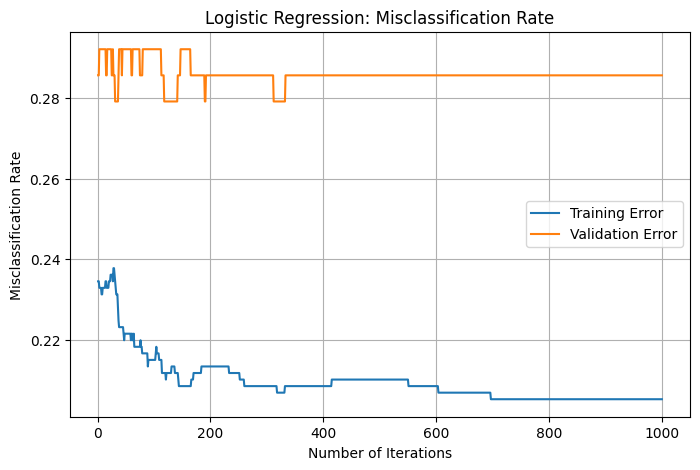

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, iterations + 1), training_errors, label="Training Error")
plt.plot(range(1, iterations + 1), validation_errors, label="Validation Error")
plt.xlabel("Number of Iterations")
plt.ylabel("Misclassification Rate")
plt.title("Logistic Regression: Misclassification Rate")
plt.legend()
plt.grid(True)
plt.show()

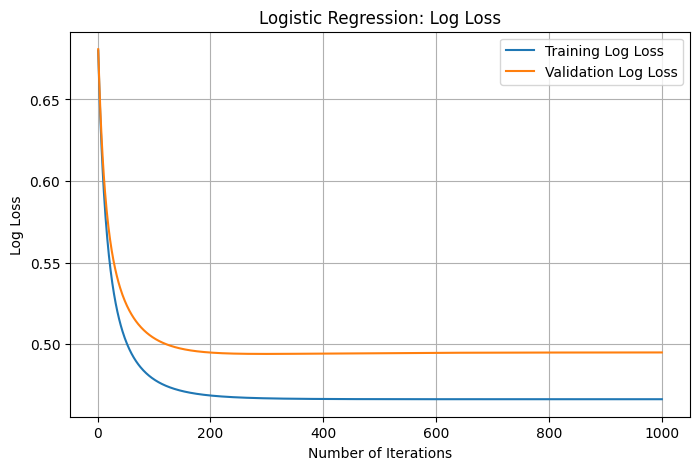

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, iterations + 1), training_losses, label="Training Log Loss")
plt.plot(range(1, iterations + 1), validation_losses, label="Validation Log Loss")
plt.xlabel("Number of Iterations")
plt.ylabel("Log Loss")
plt.title("Logistic Regression: Log Loss")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
naive_bayes = GaussianNB()
naive_bayes.fit(X_train, y_train)
naive_bayes_predictions = naive_bayes.predict(X_validation)

In [10]:
def show_metrics(model_name, y_true, y_pred):
    print(model_name)
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred), 4))
    print("Recall:", round(recall_score(y_true, y_pred), 4))
    print("F1 Score:", round(f1_score(y_true, y_pred), 4))
    print()


show_metrics("Logistic Regression", y_validation, logistic_predictions)
show_metrics("Gaussian Naive Bayes", y_validation, naive_bayes_predictions)

Logistic Regression
Confusion Matrix:
[[82 18]
 [26 28]]
Accuracy: 0.7143
Precision: 0.6087
Recall: 0.5185
F1 Score: 0.56

Gaussian Naive Bayes
Confusion Matrix:
[[74 26]
 [19 35]]
Accuracy: 0.7078
Precision: 0.5738
Recall: 0.6481
F1 Score: 0.6087

